# News Topic Classifier using BERT

## Problem Statement
Automatically classify news headlines into predefined categories using a transformer-based NLP model.

## Objective
The goal of this task is to fine-tune the **BERT transformer model** to classify news headlines into topic categories using the **AG News Dataset**.

## Categories in AG News Dataset
1. World
2. Sports
3. Business
4. Sci/Tech

## Key Tasks
- Load AG News dataset
- Preprocess and tokenize text
- Fine-tune BERT model
- Evaluate using Accuracy and F1-score
- Deploy model using Gradio

## Skills Demonstrated
- Natural Language Processing (NLP)
- Transformer Models
- Transfer Learning
- Model Evaluation
- Lightweight Deployment

# **INSTALL LIBRARIES**

In [1]:
# Install required libraries for NLP and transformers

!pip install transformers
!pip install datasets
!pip install evaluate
!pip install scikit-learn
!pip install gradio
!pip install -U transformers datasets evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 105.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 520.7/520.7 kB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 20.8 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.0.0
    Uninstalling transformers-5.0.0:
      Successfully uninstalled transformers-5.0.0


# **IMPORT LIBRARIES**

In [2]:
# Import necessary Python libraries

import torch
import pandas as pd
import numpy as np

from datasets import load_dataset
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import Trainer, TrainingArguments

from sklearn.metrics import accuracy_score, f1_score
import evaluate

import matplotlib.pyplot as plt
import gradio as gr

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


# **LOAD DATASET**

In [3]:
# Load the AG News dataset from HuggingFace

dataset = load_dataset("ag_news")

# Display dataset structure
dataset

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

# **DATASET EXPLORATION**

In [4]:
# Convert training dataset to pandas dataframe for inspection

df = pd.DataFrame(dataset['train'])

# Display first 5 rows
df.head()

,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [5]:
# Check class distribution

df['label'].value_counts()

,count
label,
2,30000
3,30000
1,30000
0,30000


In [6]:
# Label mapping
label_names = ['World', 'Sports', 'Business', 'Sci/Tech']

print(label_names)

['World', 'Sports', 'Business', 'Sci/Tech']


# **TOKENIZATION (PREPROCESSING)**

In [7]:
# Load BERT tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# Tokenization function
def tokenize_function(example):

    return tokenizer(
        example["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

# Apply tokenizer to dataset
tokenized_dataset = dataset.map(tokenize_function, batched=True)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [8]:
# Set format for PyTorch

tokenized_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

tokenized_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
})

# **LOAD BERT MODEL**

In [9]:
# Load BERT model for classification

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=4
)

print("Model Loaded")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model Loaded


# **TRAINING ARGUMENTS**

In [10]:
training_args = TrainingArguments(

    output_dir="./results",

    learning_rate=2e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=2,

    logging_dir="./logs",

)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


# **EVALUATION METRICS**

In [11]:
# Function to compute accuracy and F1 score

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, predictions)

    f1 = f1_score(labels, predictions, average="weighted")

    return {
        "accuracy": acc,
        "f1_score": f1
    }

# **TRAINER**

In [12]:
# Define Trainer API

trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_dataset["train"],

    eval_dataset=tokenized_dataset["test"],

    compute_metrics=compute_metrics,

)

# **TRAIN MODEL**

In [13]:
# Start training

trainer.train()

Step,Training Loss
500,0.412495
1000,0.262651
1500,0.236599
2000,0.226804
2500,0.232738
3000,0.238312
3500,0.213139
4000,0.213236
4500,0.203638
5000,0.197831


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (22 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=15000, training_loss=0.17938927866617838, metrics={'train_runtime': 7155.2549, 'train_samples_per_second': 33.542, 'train_steps_per_second': 2.096, 'total_flos': 1.578694680576e+16, 'train_loss': 0.17938927866617838, 'epoch': 2.0})

# **MODEL EVALUATION**

In [16]:
# Evaluate model performance
results = trainer.evaluate()

print("Evaluation Results:")
print(results)

Step,Training Loss,Validation Loss,Accuracy,F1 Score
22,No log,0.217420,0.944079,0.944139


Evaluation Results:
{'eval_loss': 0.2174197882413864, 'eval_accuracy': 0.944078947368421, 'eval_f1_score': 0.9441390591265683}


# **VISUALIZATION**

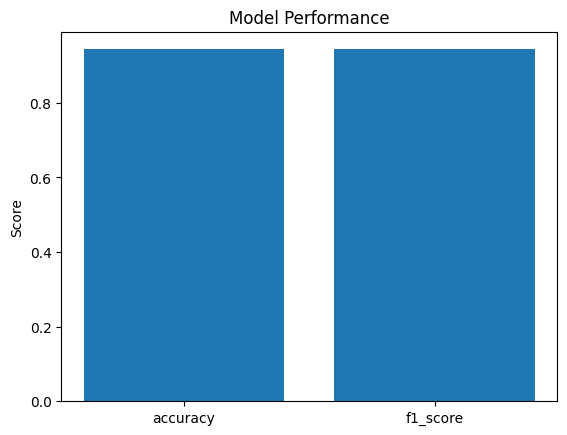

In [17]:
# Example visualization of evaluation metrics

metrics = ["accuracy", "f1_score"]
values = [results['eval_accuracy'], results['eval_f1_score']]

plt.bar(metrics, values)
plt.title("Model Performance")
plt.ylabel("Score")
plt.show()

# **PREDICTION FUNCTION**

In [18]:
# Prediction function

def predict_news(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    outputs = model(**inputs)

    logits = outputs.logits

    predicted_class = torch.argmax(logits).item()

    return label_names[predicted_class]

# **TEST PREDICTION**

In [22]:
# Detect device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to device
model.to(device)

def predict_news(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    # Move inputs to same device as model
    inputs = {key: value.to(device) for key, value in inputs.items()}

    outputs = model(**inputs)

    logits = outputs.logits

    predicted_class = torch.argmax(logits).item()

    return label_names[predicted_class]

In [27]:
# Test prediction

predict_news("US president meets Chinese leader to discuss trade agreement")

'World'

# **GRADIO DEPLOYMENT**

In [24]:
# Create Gradio interface for live interaction

interface = gr.Interface(

    fn=predict_news,

    inputs="text",

    outputs="text",

    title="News Topic Classifier (BERT)",

    description="Enter a news headline to classify its topic."
)

interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5ad321c26e8bfecf69.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# **Testing the Model with Probability Graph**

In [28]:
import torch
import matplotlib.pyplot as plt

# Label names
label_names = ['World', 'Sports', 'Business', 'Sci/Tech']

# Device detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

def predict_with_graph(text):

    # Tokenize input
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    # Move tensors to same device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Disable gradient for inference
    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits

    # Convert logits → probabilities
    probs = torch.nn.functional.softmax(logits, dim=-1).cpu().numpy()[0]

    # Predicted label
    predicted_class = label_names[probs.argmax()]

    print("News Headline:", text)
    print("Predicted Category:", predicted_class)

    # Plot probability graph
    plt.figure(figsize=(6,4))
    plt.bar(label_names, probs)
    plt.title("Prediction Probability Distribution")
    plt.ylabel("Probability")
    plt.xlabel("News Category")
    plt.show()

News Headline: US president meets Chinese leader to discuss trade agreement
Predicted Category: World


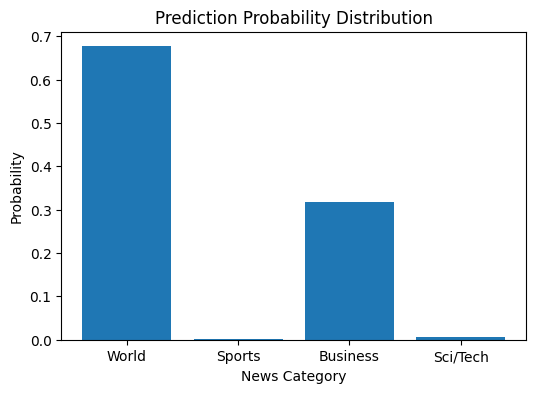

In [30]:
predict_with_graph("US president meets Chinese leader to discuss trade agreement")

# **FINAL SUMMARY**

# Final Summary

## Model Used
BERT (bert-base-uncased)

## Dataset
AG News Dataset

## Evaluation Metrics
- Accuracy
- F1 Score

## Observations
- BERT performs well on short text classification tasks
- Fine-tuning transformer models significantly improves accuracy
- The model can successfully classify news headlines into topic categories.

## Applications
- News aggregation platforms
- Content filtering
- Automatic tagging of articles
- Media monitoring systems